# A7 Part 3: Fine-Tuning Our Small Language Model
**INFO 490 MG, Team 2 (Unleased)**

Part 2 gave the SLM extra information *without* changing its weights (RAG). Here we do the opposite: we **continue training the same SLM on new examples** and check whether its answers change.

**Starting point.** The SLM selected in Part 1 (Experiment 5: embedding 96, 4 heads, 2 layers, feed-forward 384, context 32, 232,155 parameters), loaded from the original `selected_slm.pt`. It is *not* a newly initialized model, and the checkpoint file is never overwritten. The model class, tokenizer, corpus and `generate_text` are the unchanged class code.

**How the class fine-tuning procedure (Week 6 notebook) maps onto our SLM**

| Class notebook (Hugging Face TinyStories-8M) | Here (our character-level SLM) |
|---|---|
| Question/answer pairs, prompt `Question: ...` then `Answer:` | Pairs formatted `ask. <question>` newline `reply. <answer>` newline (the same labels as the RAG prompts; `q`, `z`, capitals and digits do not exist in the SLM's alphabet) |
| Loss masking: question tokens get label `-100`, only answer tokens count | The same: prompt characters are masked with `-100`, only answer characters (and the closing newline) count |
| One example per step, `AdamW`, learning rate 2e-4 | `AdamW`, the same learning rate 2e-4, but each step uses a batch of 16 training windows (see below) |
| Track one weight tensor to prove it changed | The same, plus a checksum of *all* weights |
| Compare answers before and after on seen and unseen questions | The same, plus a multi-seed consistency check |

**Compatibility adjustment for the 32-character window.** A formatted example is 60 to 90 characters, longer than the SLM's 32-character window, so one example becomes many *windows*: for every answer character, the 32 characters before it are the input and that answer character is the target. This is exactly the situation the model faces when it generates (it only ever sees the last 32 characters).

**How to run:** `python -m jupyter nbconvert --to notebook --execute --inplace a7_finetune_slm.ipynb`. Put Part 1's `selected_slm.pt` in `slm_results/` (or leave it in `../a7-rag/slm_results/`). Fine-tuning takes about 10 seconds on a CPU. Model weights are git-ignored and are not submitted.


## Setup

In [1]:
import math, random, time, platform, json, os, hashlib, re
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)           # same as Part 1
DEVICE = torch.device("cpu")       # same as Part 1: CPU only
OUT = Path("slm_results"); OUT.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", None, "display.width", 250)

print("PyTorch:", torch.__version__, "| Device:", DEVICE, "| Machine:", platform.platform())

PyTorch: 2.14.1 | Device: cpu | Machine: macOS-26.6.2-arm64-arm-64bit-Mach-O


## The SLM, rebuilt exactly as in Part 1 (class code, unchanged)

In [2]:
# Architecture of the SLM selected in Part 1 (Experiment 5), see llm-test/a7-part2/selected_slm.json
BATCH_SIZE = 16
CONTEXT_LENGTH = 32
EMBEDDING_DIM = 96
NUM_HEADS = 4
NUM_LAYERS = 2
FEEDFORWARD_DIM = 384
LEARNING_RATE = 0.001
TRAINING_STEPS = 30000

p1 = Path("../a7-part2/selected_slm.json")
if p1.exists():                    # make sure we really match what Part 1 selected
    sel = json.load(open(p1))["config"]
    assert (sel["embedding_dim"], sel["num_heads"], sel["num_layers"], sel["feedforward_dim"]) == \
           (EMBEDDING_DIM, NUM_HEADS, NUM_LAYERS, FEEDFORWARD_DIM)
    print("Matches Part 1 selected_slm.json:", sel)

# ---- Training corpus (class Cell 3): 20 sentences repeated 100 times ----
sentences = [
    "students build django applications.", "students learn python programming.",
    "students develop artificial intelligence systems.", "language models predict the next token.",
    "transformers use attention mechanisms.", "neural networks learn from training data.",
    "machine learning models contain parameters.", "the professor teaches artificial intelligence.",
    "students create innovative startup applications.", "django applications use models and views.",
    "training changes the weights of a neural network.", "inference uses previously learned parameters.",
    "the university offers courses in informatics.", "students experiment with language models.",
    "artificial intelligence can generate text.", "the model predicts characters using probabilities.",
    "attention helps models use contextual information.", "python is useful for machine learning research.",
    "the students are building useful software products.", "small language models can run on local computers."]
text = ("\n".join(sentences) + "\n") * 100
CORPUS_SENTENCES = set(sentences)
CORPUS_WORDS = {w for w in re.findall(r"[a-z]+", text)}

# ---- Character-level tokenizer (class Cell 4) ----
chars = sorted(set(text))
VOCAB_SIZE = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}
def encode(s): return [stoi[ch] for ch in s]
def decode(ids): return "".join(itos[int(i)] for i in ids)

data = torch.tensor(encode(text), dtype=torch.long)
split = int(0.9 * len(data))
train_data, val_data = data[:split], data[split:]

def get_batch(source):
    starts = torch.randint(0, len(source) - CONTEXT_LENGTH, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LENGTH] for i in starts])
    y = torch.stack([source[i + 1:i + CONTEXT_LENGTH + 1] for i in starts])
    return x.to(DEVICE), y.to(DEVICE)

print("Characters in corpus:", len(text), "(Part 1: 90,300)")
print("Vocabulary size:", VOCAB_SIZE, "->", repr("".join(chars)))
print("Letters the model has never seen:", [c for c in "abcdefghijklmnopqrstuvwxyz" if c not in stoi])

# ---- Transformer (class Cells 9A and 9B) ----
class TransformerBlock(nn.Module):
    def __init__(self, embedding_dim, num_heads, feedforward_dim):
        super().__init__()
        self.attention = nn.MultiheadAttention(embed_dim=embedding_dim, num_heads=num_heads, dropout=0.0, batch_first=True)
        self.ln1 = nn.LayerNorm(embedding_dim)
        self.ln2 = nn.LayerNorm(embedding_dim)
        self.feedforward = nn.Sequential(nn.Linear(embedding_dim, feedforward_dim), nn.ReLU(),
                                         nn.Linear(feedforward_dim, embedding_dim))
    def forward(self, x):
        T = x.shape[1]
        mask = torch.triu(torch.ones(T, T, device=x.device, dtype=torch.bool), diagonal=1)
        normalized = self.ln1(x)
        attended, _ = self.attention(normalized, normalized, normalized, attn_mask=mask, need_weights=False)
        x = x + attended
        x = x + self.feedforward(self.ln2(x))
        return x

class TinyTransformerLM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, num_heads, num_layers, feedforward_dim, context_length):
        super().__init__()
        self.context_length = context_length
        self.token_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.position_embedding = nn.Embedding(context_length, embedding_dim)
        self.blocks = nn.Sequential(*[TransformerBlock(embedding_dim, num_heads, feedforward_dim) for _ in range(num_layers)])
        self.ln_final = nn.LayerNorm(embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)
    def forward(self, input_ids):
        B, T = input_ids.shape
        if T > self.context_length:
            raise ValueError("Input sequence exceeds context length.")
        positions = torch.arange(T, device=input_ids.device)
        x = self.token_embedding(input_ids) + self.position_embedding(positions)
        x = self.blocks(x)
        x = self.ln_final(x)
        return self.output(x)

# ---- Generation, loss, evaluation (class Cells 12A, 13A, 14G) ----
@torch.no_grad()
def generate_text(model, prompt, max_new_tokens=100, temperature=1.0):
    if temperature <= 0:
        raise ValueError("Temperature must be greater than zero.")
    was_training = model.training
    model.eval()
    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)
    for _ in range(max_new_tokens):
        context = ids[:, -model.context_length:]          # the model only ever sees the last 32 characters
        logits = model(context)
        next_logits = logits[:, -1, :] / temperature
        probabilities = F.softmax(next_logits, dim=-1)
        next_id = torch.multinomial(probabilities, num_samples=1)
        ids = torch.cat([ids, next_id], dim=1)
    if was_training:
        model.train()
    return decode(ids[0].tolist())

def calculate_loss(logits, targets):
    B, T, V = logits.shape
    return F.cross_entropy(logits.reshape(B * T, V), targets.reshape(B * T))

@torch.no_grad()
def evaluate(model, source, batches=20):
    model.eval()
    losses = []
    for _ in range(batches):
        x, y = get_batch(source)
        losses.append(calculate_loss(model(x), y).item())
    model.train()
    return sum(losses) / len(losses)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

Matches Part 1 selected_slm.json: {'embedding_dim': 96, 'num_heads': 4, 'num_layers': 2, 'feedforward_dim': 384}
Characters in corpus: 90300 (Part 1: 90,300)
Vocabulary size: 27 -> '\n .abcdefghijklmnoprstuvwxy'
Letters the model has never seen: ['q', 'z']


## Load the original Part 1 checkpoint
We keep two copies in memory, both loaded from the same file: `slm` (never touched, used for every "before" result) and `ft` (the copy that will be fine-tuned). The fingerprint is a SHA-256 over every weight, so we can prove which checkpoint we used and that the original did not change.

In [3]:
import copy, hashlib
CKPT = next((p for p in [Path("slm_results/selected_slm.pt"), Path("../a7-rag/slm_results/selected_slm.pt")] if p.exists()), None)
assert CKPT, "Put Part 1's selected_slm.pt in slm_results/ (checkpoints are not in GitHub)."
saved = torch.load(CKPT, map_location=DEVICE, weights_only=True)
assert saved["vocab"] == chars, "checkpoint vocabulary does not match the tokenizer"
CFG = saved["config"]
print("Checkpoint:", CKPT, "| config:", CFG)

def new_model():
    return TinyTransformerLM(vocab_size=VOCAB_SIZE, embedding_dim=CFG["embedding_dim"], num_heads=CFG["num_heads"],
                             num_layers=CFG["num_layers"], feedforward_dim=CFG["feedforward_dim"],
                             context_length=CFG["context_length"]).to(DEVICE)

def fingerprint(model):
    h = hashlib.sha256()
    for name, tensor in model.state_dict().items():
        h.update(name.encode()); h.update(tensor.detach().cpu().numpy().tobytes())
    return h.hexdigest()

slm = new_model(); slm.load_state_dict(saved["model_state"]); slm.eval()      # the ORIGINAL model: never trained further
ft = new_model();  ft.load_state_dict(saved["model_state"])                   # starts from the SAME trained weights, not a new init

FP_ORIGINAL = fingerprint(slm)
PART2_FP = "e331f6e0eddc2ce8463a513412aa2dca8f7584badc0d1ec9d27237cd00cd62d6"   # fingerprint printed by the RAG notebook
print("Parameters:", f"{count_parameters(slm):,}", "| fingerprint:", FP_ORIGINAL[:32], "...")
print("Same checkpoint as the RAG notebook (Part 2):", FP_ORIGINAL == PART2_FP, "| fine-tuned copy starts identical to the original:", fingerprint(ft) == FP_ORIGINAL)

Checkpoint: ../a7-rag/slm_results/selected_slm.pt | config: {'embedding_dim': 96, 'num_heads': 4, 'num_layers': 2, 'feedforward_dim': 384, 'context_length': 32}
Parameters: 232,155 | fingerprint: e331f6e0eddc2ce8463a513412aa2dca ...
Same checkpoint as the RAG notebook (Part 2): True | fine-tuned copy starts identical to the original: True


## Step 3.1: Create our own fine-tuning examples
**Same topic and facts as the RAG knowledge base** (the made-up Unleased service: pricing, verification, visits, privacy, membership, refunds, favorites, support). 14 question/answer examples:
- **5 "seen" examples = the five evaluation questions from Part 2, word for word.** The class notebook also trains on its probe questions. This means improvement on Q1 to Q5 shows the model can *memorize* the answers; it does not prove it understands them.
- **5 paraphrases** of the same five facts (different wording, same answer), so the model sees each fact asked two ways.
- **4 examples about other facts** in the knowledge base.

To test whether anything was learned beyond memorizing, we also hold out **5 unseen questions** (new wordings that are *not* in the training set), and 4 **out-of-knowledge-base questions** whose answer is not in our documents at all.

All text is written inside the SLM's 27-character alphabet (no `q`, `z`, digits, capitals or punctuation other than `.`), so it can be encoded.

In [4]:
TRAIN = [
    # (question, answer, kind)
    ("how much does it cost to post a listing",      "posting a listing costs ten dollars a month.",  "seen: evaluation question Q1"),
    ("what do i need to get a verified badge",       "you need a valid edu email address.",          "seen: evaluation question Q2"),
    ("when is the street address shown to a renter", "after the lister accepts a renter.",            "seen: evaluation question Q3"),
    ("how long is a visit slot",                     "a visit slot lasts one hour.",                  "seen: evaluation question Q4"),
    ("what do premium members get",                  "early alerts for new listings near campus.",    "seen: evaluation question Q5"),
    ("what is the price of posting a listing",       "posting a listing costs ten dollars a month.",  "paraphrase of Q1"),
    ("how do i get the verified badge",              "you need a valid edu email address.",          "paraphrase of Q2"),
    ("when can a renter see the street address",     "after the lister accepts a renter.",            "paraphrase of Q3"),
    ("how long does a visit last",                   "a visit slot lasts one hour.",                  "paraphrase of Q4"),
    ("what perks do premium members have",           "early alerts for new listings near campus.",    "paraphrase of Q5"),
    ("when are refunds given",                       "refunds are given within seven days.",          "other fact (refunds)"),
    ("can renters save listings",                    "renters can save listings to a favorites list.", "other fact (favorites)"),
    ("when does support answer messages",            "support answers messages on weekdays.",         "other fact (support)"),
    ("is browsing listings free",                    "browsing listings is free.",                    "other fact (pricing)"),
]
EVAL = [  # the five Part 2 evaluation questions, with the keywords a correct answer must contain
    ("Q1", "how much does it cost to post a listing",      ["ten", "dollars", "month"]),
    ("Q2", "what do i need to get a verified badge",       ["edu", "email"]),
    ("Q3", "when is the street address shown to a renter", ["accepts", "lister"]),
    ("Q4", "how long is a visit slot",                     ["one", "hour"]),
    ("Q5", "what do premium members get",                  ["early", "alerts"]),
]
UNSEEN = [  # NOT in the training set
    ("U1", "what does a listing cost per month",           ["ten", "dollars", "month"]),
    ("U2", "which email do i need for the badge",          ["edu", "email"]),
    ("U3", "how long can i book a visit",                  ["one", "hour"]),
    ("U4", "what do members with premium receive",         ["early", "alerts"]),
    ("U5", "who can see the street address",               ["accepts", "lister"]),
]
OUT_OF_KB = [  # the knowledge base has no answer to these
    ("X1", "how much is a premium membership"), ("X2", "where is the support office"),
    ("X3", "can i pay with a credit card"),     ("X4", "how many listings can one lister post")]

# Compatibility with the SLM tokenizer, and sanity checks on the data split
for q, a, kind in TRAIN:
    assert set(q) <= set(stoi) and set(a) <= set(stoi), f"cannot encode: {q!r} / {a!r}"
for group in (EVAL, UNSEEN, OUT_OF_KB):
    for item in group:
        assert set(item[1]) <= set(stoi), item
train_questions = {q for q, _, _ in TRAIN}
assert all(q in train_questions for _, q, _ in EVAL), "the five evaluation questions should be in the training set"
assert not any(q in train_questions for _, q, _ in UNSEEN), "unseen questions must not be in the training set"
qs_csv = Path("../a7-rag/questions.csv")
if qs_csv.exists():
    assert [q for _, q, _ in EVAL] == pd.read_csv(qs_csv).question.tolist(), "evaluation questions differ from Part 2"
    print("The five evaluation questions are identical to Part 2's questions.csv")
print(f"{len(TRAIN)} training examples | {len(UNSEEN)} unseen questions | {len(OUT_OF_KB)} out-of-knowledge-base questions")
examples = pd.DataFrame(TRAIN, columns=["question", "answer", "kind"]); examples.insert(0, "id", [f"ex{i:02d}" for i in range(1, len(TRAIN) + 1)])
examples.to_csv("finetune_examples.csv", index=False)
examples

The five evaluation questions are identical to Part 2's questions.csv
14 training examples | 5 unseen questions | 4 out-of-knowledge-base questions


,id,question,answer,kind
0,ex01,how much does it cost to post a listing,posting a listing costs ten dollars a month.,seen: evaluation question Q1
1,ex02,what do i need to get a verified badge,you need a valid edu email address.,seen: evaluation question Q2
2,ex03,when is the street address shown to a renter,after the lister accepts a renter.,seen: evaluation question Q3
3,ex04,how long is a visit slot,a visit slot lasts one hour.,seen: evaluation question Q4
4,ex05,what do premium members get,early alerts for new listings near campus.,seen: evaluation question Q5
5,ex06,what is the price of posting a listing,posting a listing costs ten dollars a month.,paraphrase of Q1
6,ex07,how do i get the verified badge,you need a valid edu email address.,paraphrase of Q2
7,ex08,when can a renter see the street address,after the lister accepts a renter.,paraphrase of Q3
8,ex09,how long does a visit last,a visit slot lasts one hour.,paraphrase of Q4
9,ex10,what perks do premium members have,early alerts for new listings near campus.,paraphrase of Q5


## Step 3.2: Test the SLM before fine-tuning
Loaded from the original checkpoint, with the same prompt format and generation settings as Part 2 (temperature 0.7, 60 new characters, seed reset to 42 before every generation). These answers must therefore be **identical to Part 2's no-RAG baseline**, and the cell checks that.

In [5]:
GEN_TEMPERATURE, MAX_NEW_TOKENS = 0.7, 60          # Part 1 / Part 2 generation settings

def answer(model, question, seed=SEED, temperature=GEN_TEMPERATURE):
    prompt = f"ask. {question}\nreply. "
    torch.manual_seed(seed)
    return generate_text(model, prompt, max_new_tokens=MAX_NEW_TOKENS, temperature=temperature)[len(prompt):]

def first_line(response): return response.split("\n")[0]
def words(s): return re.findall(r"[a-z]+", s.lower())
def is_correct(response, keywords):
    # correct = the first line of the answer contains every gold keyword
    return set(keywords) <= set(words(first_line(response)))

before = pd.DataFrame([{"Question": qid, "Question text": q, "Response Before Fine-Tuning": answer(slm, q),
                        "Correct before": is_correct(answer(slm, q), kw)} for qid, q, kw in EVAL])
before.to_csv("before_finetuning.csv", index=False)

baseline_csv = Path("../a7-rag/baseline_no_rag.csv")
if baseline_csv.exists():
    part2 = pd.read_csv(baseline_csv)["SLM Response Without RAG"].tolist()
    assert before["Response Before Fine-Tuning"].tolist() == part2, "before-fine-tuning answers differ from the Part 2 no-RAG baseline"
    print("The before-fine-tuning answers are identical to Part 2's no-RAG baseline (same checkpoint, settings and seeds).")
before[["Question", "Question text", "Response Before Fine-Tuning", "Correct before"]]

The before-fine-tuning answers are identical to Part 2's no-RAG baseline (same checkpoint, settings and seeds).


,Question,Question text,Response Before Fine-Tuning,Correct before
0,Q1,how much does it cost to post a listing,offers courses in informatics.\nstudents experiment with lang,False
1,Q2,what do i need to get a verified badge,the weigention generate text.\nthe model predicts characters,False
2,Q3,when is the street address shown to a renter,offers courses in informatics.\nstudents experiment with lang,False
3,Q4,how long is a visit slot,offers courses in informatics.\nstudents experiment with lang,False
4,Q5,what do premium members get,offers courses in informatics.\nstudents experiment with lang,False


## Step 3.3: Fine-tune the SLM
**Training windows and loss masking** (class cells on tokenization and `-100` labels). For each answer character at position *i* of `ask. <question>\nreply. <answer>\n`, the input is the 32 characters before it and the target is shifted by one. Targets that fall inside the prompt get label `-100` and are ignored by the loss; only the answer characters and the closing newline are learned.

In [6]:
def make_windows(pairs):
    X, Y, owners = [], [], []
    for n, (q, a, _) in enumerate(pairs):
        prompt = f"ask. {q}\nreply. "
        s = prompt + a + "\n"
        ids = encode(s)
        for i in range(len(prompt), len(s)):            # one window per answer character
            start = i - CONTEXT_LENGTH
            assert start >= 0, "prompt shorter than the context window"
            x = ids[start:start + CONTEXT_LENGTH]
            y = ids[start + 1:start + CONTEXT_LENGTH + 1]
            y = [t if (start + 1 + j) >= len(prompt) else -100 for j, t in enumerate(y)]   # mask prompt characters
            X.append(x); Y.append(y); owners.append(n)
    return torch.tensor(X, device=DEVICE), torch.tensor(Y, device=DEVICE), owners

X, Y, owners = make_windows(TRAIN)
print("Training windows:", len(X), "from", len(TRAIN), "examples |", "window length:", X.shape[1])

# Show one window like the class notebook shows one tokenized example
k = 30
shown_target = "".join(itos[int(t)] if t != -100 else "_" for t in Y[k])
print("\nExample window", k, "(from example", owners[k] + 1, ")")
print("input chars :", repr(decode(X[k])))
print("target chars:", repr(shown_target), "(_ = masked prompt character, ignored by the loss)")
print("masked:", int((Y[k] == -100).sum()), "| used for loss:", int((Y[k] != -100).sum()))

def masked_loss(logits, targets):
    return F.cross_entropy(logits.reshape(-1, VOCAB_SIZE), targets.reshape(-1), ignore_index=-100)

Training windows: 525 from 14 examples | window length: 32

Example window 30 (from example 1 )
input chars : '. posting a listing costs ten do'
target chars: '_posting a listing costs ten dol' (_ = masked prompt character, ignored by the loss)
masked: 1 | used for loss: 31


{'learning_rate': 0.0002, 'steps': 1500, 'batch_windows': 16, 'optimizer': 'AdamW'}


Initial fine-tuning loss (answer characters, all 525 windows): 8.1255


  Fine-tuning step     1/1500 | batch loss: 7.9016


  Fine-tuning step   251/1500 | batch loss: 0.3892


  Fine-tuning step   501/1500 | batch loss: 0.0995


  Fine-tuning step   751/1500 | batch loss: 0.1022


  Fine-tuning step  1001/1500 | batch loss: 0.0444


  Fine-tuning step  1251/1500 | batch loss: 0.0712


  Fine-tuning step  1500/1500 | batch loss: 0.0702

Fine-tuning time: 6.8 s | final fine-tuning loss (all windows): 0.0568


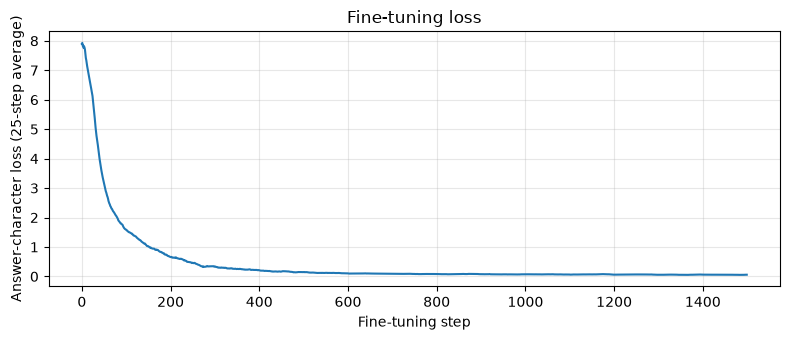

In [7]:
# ---- Fine-tuning configuration (recorded) ----
FT_LEARNING_RATE = 2e-4      # the class fine-tuning notebook's learning rate
FT_STEPS = 1500              # optimizer updates
FT_BATCH_WINDOWS = 16        # windows per update (same batch size as Part 1)
print({"learning_rate": FT_LEARNING_RATE, "steps": FT_STEPS, "batch_windows": FT_BATCH_WINDOWS, "optimizer": "AdamW"})

@torch.no_grad()
def training_set_loss(model):
    model.eval(); value = masked_loss(model(X), Y).item(); model.train(); return value

# Class cell: track one weight tensor so we can prove it changed
tracked_name, tracked_param = next((n, p) for n, p in ft.named_parameters() if p.requires_grad)
weights_before = tracked_param.detach().clone()
state_before = {k: v.detach().clone() for k, v in ft.state_dict().items()}
FP_BEFORE_FT = fingerprint(ft)
initial_loss = training_set_loss(ft)
print(f"Initial fine-tuning loss (answer characters, all {len(X)} windows): {initial_loss:.4f}")

# ---- Training loop (class cell: AdamW, loss.backward(), optimizer.step()) ----
optimizer = torch.optim.AdamW(ft.parameters(), lr=FT_LEARNING_RATE)
generator = torch.Generator().manual_seed(SEED)
ft.train()
loss_history = []
start = time.perf_counter()
for step in range(FT_STEPS):
    idx = torch.randint(0, len(X), (FT_BATCH_WINDOWS,), generator=generator)
    optimizer.zero_grad(set_to_none=True)
    loss = masked_loss(ft(X[idx]), Y[idx])
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if step % 250 == 0 or step == FT_STEPS - 1:
        print(f"  Fine-tuning step {step + 1:>5}/{FT_STEPS} | batch loss: {loss.item():.4f}")
fine_tune_seconds = time.perf_counter() - start
ft.eval()
final_loss = training_set_loss(ft)
print(f"\nFine-tuning time: {fine_tune_seconds:.1f} s | final fine-tuning loss (all windows): {final_loss:.4f}")

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 3.5))
plt.plot(pd.Series(loss_history).rolling(25, min_periods=1).mean())
plt.xlabel("Fine-tuning step"); plt.ylabel("Answer-character loss (25-step average)")
plt.title("Fine-tuning loss"); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("finetune_loss_curve.png", dpi=150); plt.show()

### Verify that the weights changed (class weight-check cell, plus a checksum of every weight)

In [8]:
change = (dict(ft.named_parameters())[tracked_name].detach() - weights_before).abs()
print("Tracked tensor:", tracked_name)
print("  mean absolute change:", f"{change.mean().item():.6f}", "| maximum:", f"{change.max().item():.6f}",
      "| elements changed:", int((change > 0).sum()), "/", change.numel())

FP_AFTER_FT = fingerprint(ft)
changed = sum(int((ft.state_dict()[k] != state_before[k]).sum()) for k in state_before)
total = sum(v.numel() for v in state_before.values())
WEIGHTS_UPDATED = FP_AFTER_FT != FP_BEFORE_FT
print("Whole model: fingerprint before", FP_BEFORE_FT[:16], "| after", FP_AFTER_FT[:16], "| different:", WEIGHTS_UPDATED)
print(f"Individual weights that changed: {changed:,} of {total:,}")

# The original model and the checkpoint file are untouched
assert fingerprint(slm) == FP_ORIGINAL, "the original model was modified"
print("Original in-memory model unchanged:", fingerprint(slm) == FP_ORIGINAL)
torch.save({"model_state": ft.state_dict(), "vocab": chars, "config": CFG}, OUT / "finetuned_slm.pt")   # git-ignored (*.pt)
print("Fine-tuned weights saved to", OUT / "finetuned_slm.pt", "(not submitted; the original", CKPT, "was not overwritten)")

Tracked tensor: token_embedding.weight
  mean absolute change: 0.013116 | maximum: 0.059597 | elements changed: 2592 / 2592
Whole model: fingerprint before e331f6e0eddc2ce8 | after c5713cd56397726f | different: True
Individual weights that changed: 232,155 of 232,155
Original in-memory model unchanged: True
Fine-tuned weights saved to slm_results/finetuned_slm.pt (not submitted; the original ../a7-rag/slm_results/selected_slm.pt was not overwritten)


### Responses after fine-tuning, and the Before / After table

In [9]:
rows = []
for (qid, q, kw), b in zip(EVAL, before.itertuples()):
    after = answer(ft, q)
    rows.append({"Question": qid, "Question text": q, "Before Fine-Tuning": b._3, "After Fine-Tuning": after,
                 "Correct before": b._4, "Correct after": is_correct(after, kw)})
before_after = pd.DataFrame(rows)
before_after.to_csv("finetune_before_after.csv", index=False)
print("Correct before:", int(before_after["Correct before"].sum()), "of 5 | correct after:", int(before_after["Correct after"].sum()), "of 5")
before_after[["Question", "Before Fine-Tuning", "After Fine-Tuning", "Correct before", "Correct after"]]

Correct before: 0 of 5 | correct after: 5 of 5


,Question,Before Fine-Tuning,After Fine-Tuning,Correct before,Correct after
0,Q1,offers courses in informatics.\nstudents experiment with lang,posting a listing costs ten dollars a month.\nmacccouppsiveni,False,True
1,Q2,the weigention generate text.\nthe model predicts characters,you need a valid edu email address.\nstudents buld djaramethi,False,True
2,Q3,offers courses in informatics.\nstudents experiment with lang,after the lister accepts a renter.\nthe mofts can save listin,False,True
3,Q4,offers courses in informatics.\nstudents experiment with lang,a visit slot lasts one hour.\ntran lica calerts for new listi,False,True
4,Q5,offers courses in informatics.\nstudents experiment with lang,early alerts for new listings near campus.\nstude a visit slo,False,True


### The record of the fine-tuning run (the metrics table the assignment asks for)

In [10]:
metrics = pd.DataFrame({"Metric": ["SLM Architecture", "Starting checkpoint", "Number of Fine-Tuning Examples", "Learning Rate", "Fine-Tuning Steps",
                                   "Initial Fine-Tuning Loss", "Final Fine-Tuning Loss", "Fine-Tuning Time", "Were Weights Updated?"],
                        "Result": [f"Part 1 Experiment 5: embedding {CFG['embedding_dim']}, {CFG['num_heads']} heads, {CFG['num_layers']} layers, feed-forward {CFG['feedforward_dim']}, context {CFG['context_length']} ({count_parameters(ft):,} parameters)",
                                   f"original Part 1 selected_slm.pt (fingerprint {FP_ORIGINAL[:12]}...), not a new initialization",
                                   f"{len(TRAIN)} question/answer examples ({len(X)} training windows, batches of {FT_BATCH_WINDOWS}), AdamW",
                                   FT_LEARNING_RATE, f"{FT_STEPS:,}", round(initial_loss, 4), round(final_loss, 4),
                                   f"{fine_tune_seconds:.1f} s",
                                   f"Yes: model checksum changed; {changed:,} of {total:,} individual weights differ; tracked tensor mean change {change.mean().item():.6f}" if WEIGHTS_UPDATED else "No"]})
metrics.to_csv("finetune_metrics.csv", index=False)
metrics

,Metric,Result
0,SLM Architecture,"Part 1 Experiment 5: embedding 96, 4 heads, 2 layers, feed-forward 384, context 32 (232,155 parameters)"
1,Starting checkpoint,"original Part 1 selected_slm.pt (fingerprint e331f6e0eddc...), not a new initialization"
2,Number of Fine-Tuning Examples,"14 question/answer examples (525 training windows, batches of 16), AdamW"
3,Learning Rate,0.0002
4,Fine-Tuning Steps,"1,500"
5,Initial Fine-Tuning Loss,8.1255
6,Final Fine-Tuning Loss,0.0568
7,Fine-Tuning Time,6.8 s
8,Were Weights Updated?,"Yes: model checksum changed; 232,155 of 232,155 individual weights differ; tracked tensor mean change 0.013116"


### More evidence for the analysis
**(a) Does it generalize, and is it consistent?** Each question is asked 10 times with 10 different random seeds (temperature 0.7). A sample is correct when its first line contains every gold keyword.
**(b) What did it forget?** The loss on the *original* training corpus before and after, and what it writes when prompted like Part 1 (`students `).
**(c) Does it invent answers?** The out-of-knowledge-base questions.

In [11]:
SEEDS = list(range(100, 110))
def consistency(model, group):
    out = []
    for item in group:
        qid, q, kw = item
        samples = [answer(model, q, seed=s) for s in SEEDS]
        out.append(sum(is_correct(r, kw) for r in samples) / len(SEEDS))
    return sum(out) / len(out), out

rows = []
for label, group in (("seen (the 5 evaluation questions)", EVAL), ("unseen (5 new wordings)", UNSEEN)):
    for name, model in (("before", slm), ("after", ft)):
        mean, per_q = consistency(model, group)
        rows.append({"Question set": label, "Model": name, "Correct answers (10 seeds each)": f"{mean:.0%}",
                     "Per question": ", ".join(f"{v:.0%}" for v in per_q)})
consistency_table = pd.DataFrame(rows)
consistency_table.to_csv("finetune_consistency.csv", index=False)
print(consistency_table.to_string(index=False))

# (b) side effects on what the model learned in Part 1
torch.manual_seed(SEED); val_before = evaluate(slm, val_data)
torch.manual_seed(SEED); val_after = evaluate(ft, val_data)
print(f"\nLoss on the original training corpus (validation split): before {val_before:.3f} -> after {val_after:.3f}")
for name, model in (("before", slm), ("after ", ft)):
    torch.manual_seed(SEED)
    print(f"'students ' prompt, {name}:", repr(generate_text(model, "students ", max_new_tokens=60, temperature=0.7)))

# (c) questions whose answer is NOT in the knowledge base
TRAINED_ANSWERS = {a for _, a, _ in TRAIN}
rows = []
for xid, q in OUT_OF_KB:
    resp = answer(ft, q)
    rows.append({"Question": xid, "Question text": q, "Response Before": first_line(answer(slm, q)), "Response After": first_line(resp),
                 "After = a trained answer (confidently reused)": first_line(resp) in TRAINED_ANSWERS})
out_of_kb = pd.DataFrame(rows); out_of_kb.to_csv("finetune_out_of_kb.csv", index=False)
print("\nOut-of-knowledge-base questions: the model reused a trained answer for",
      int(out_of_kb.iloc[:, -1].sum()), "of", len(out_of_kb))
out_of_kb

                     Question set  Model Correct answers (10 seeds each)                Per question
seen (the 5 evaluation questions) before                              0%          0%, 0%, 0%, 0%, 0%
seen (the 5 evaluation questions)  after                             98% 100%, 90%, 100%, 100%, 100%
          unseen (5 new wordings) before                              0%          0%, 0%, 0%, 0%, 0%
          unseen (5 new wordings)  after                             58%     0%, 90%, 100%, 0%, 100%

Loss on the original training corpus (validation split): before 0.126 -> after 0.634
'students ' prompt, before: 'students are building useful software products.\nsmall language models'
'students ' prompt, after : 'students are given within seven doly aredu a visme.\nlical softs neur '



Out-of-knowledge-base questions: the model reused a trained answer for 3 of 4


,Question,Question text,Response Before,Response After,After = a trained answer (confidently reused)
0,X1,how much is a premium membership,offers courses in informatics.,browsing listings is free.,True
1,X2,where is the support office,offers courses in informatics.,a renters can save listings to a favorites list.,False
2,X3,can i pay with a credit card,the next token.,browsing listings is free.,True
3,X4,how many listings can one lister post,offers courses in informatics.,a visit slot lasts one hour.,True


In [12]:
# Unseen-question answers, for reference (before vs after)
unseen_rows = [{"Question": qid, "Question text": q, "Before": first_line(answer(slm, q)), "After": first_line(answer(ft, q)),
                "Correct after": is_correct(answer(ft, q), kw)} for qid, q, kw in UNSEEN]
unseen_table = pd.DataFrame(unseen_rows); unseen_table.to_csv("finetune_unseen.csv", index=False)
unseen_table

,Question,Question text,Before,After,Correct after
0,U1,what does a listing cost per month,on is useful for machine learning research.,renters can save listings to a favorites list.,False
1,U2,which email do i need for the badge,the weigention helps models use contextual information.,you need a valid edu email address.,True
2,U3,how long can i book a visit,offers courses in informatics.,a visit slot lasts one hour.,True
3,U4,what do members with premium receive,offers courses in informatics.,refunds are given within seven days.,False
4,U5,who can see the street address,offers courses in informatics.,after the lister accepts a renter.,True


## Step 3.4: Analysis

**Setup recap:** the original Part 1 SLM (Experiment 5, 232,155 parameters) was fine-tuned for 1,500 AdamW steps at learning rate 2e-4 on 14 question/answer examples (525 training windows) about the same Unleased facts used for RAG. The "before" answers are identical to Part 2's no-RAG baseline (checked in the notebook), and the original model and checkpoint file were never modified.

| Question set | Correct before | Correct after (10 random seeds each) |
|---|---|---|
| The 5 evaluation questions (**in the training set**) | 0% | 98% |
| 5 unseen rewordings (**not** in the training set) | 0% | 58% |

**1. Did the SLM's responses change after fine-tuning?**
Yes, completely. Before, every answer was an unrelated memorized corpus sentence ("offers courses in informatics."); after, all five evaluation questions start with the right fact, for example Q1 became "posting a listing costs ten dollars a month." and Q4 "a visit slot lasts one hour."

**2. Did fine-tuning improve factual accuracy?**
On the five evaluation questions, yes: 0 of 5 correct before and 5 of 5 after (0% to 98% across 10 seeds), but those questions were in the training set, so this mostly shows memorization. On questions worded differently it only partly generalized: 58% correct (U2, U3 and U5 were right 90% to 100% of the time, U1 and U4 were never right).

**3. Did training loss decrease?**
Yes: the answer-character loss fell from 8.1255 to 0.0568 over 1,500 steps (under 10 seconds on a CPU). The starting loss is so high because the Part 1 model had never seen this kind of reply text.

**4. Were the model's weights updated?**
Yes. The checksum of the whole model changed, all 232,155 individual weights differ from the original, and the tracked tensor (`token_embedding.weight`) changed in all 2,592 elements (mean absolute change 0.0131, maximum 0.0596). The original checkpoint was not touched.

**5. Can a fine-tuned SLM still generate incorrect or unsupported information?**
Yes, in several ways we measured. (a) On unseen questions it was confidently wrong: U1 ("what does a listing cost per month") got "renters can save listings to a favorites list." and U4 got the refund policy. (b) For 3 of 4 questions whose answer is not in our documents at all, it reused a trained answer as if it knew ("how much is a premium membership" got "browsing listings is free."). (c) After the correct first line it keeps writing gibberish ("...a month.\nmacccouppsiveni"), because it never learned where to stop. (d) It forgot part of Part 1: the loss on the original corpus rose from 0.126 to 0.634 and the prompt "students " now gives garbled text ("students are given within seven doly aredu a visme.").

**Honest limits**
- The five evaluation questions were deliberately included in the training set (as the class notebook does with its "seen" probe questions), so the unseen set is the fairer test of understanding. Only 14 examples and one fine-tuning run were used.
- "Correct" means the first line of the answer contains every gold keyword; it is an automatic check, not a human grade.
- In a quick trial before the final run we tried other settings. A learning rate of 5e-4 or 1e-3 learned the answers equally well but forgot the original corpus more (validation loss 0.97 and 1.58 versus 0.63), and 500 steps at 2e-4 only half-learned them, so we kept the class learning rate with 1,500 steps.


# Part 4: Comparing Baseline, RAG, and Fine-Tuning
Three conditions, **one SLM**: the same Part 1 Experiment 5 checkpoint, the same five Part 2 evaluation questions, the same generation settings (temperature 0.7, 60 new characters, seed 42; 10 extra seeds for consistency).

- **A. Baseline:** the original SLM, no retrieval, no extra training.
- **B. RAG:** the original SLM with retrieved documents in the prompt (weights untouched). Part 2 tested two prompt layouts, so both are shown: the class-style `standard` layout at **Top-2** (the class notebook's default `TOP_K`) and the best-case `docs_last` layout at **Top-1**. We regenerate each RAG answer here from the 32-character window the SLM saw in Part 2 and check that it reproduces Part 2's recorded answer exactly.
- **C. Fine-tuning:** the Part 3 fine-tuned copy, no retrieval.
- *Extra:* the fine-tuned model **with** RAG, to give the "can they be combined?" question some evidence.

Each answer is judged on its **first line** (the model keeps writing after a newline). Measures: **factual accuracy** (share of the gold keywords present; "correct" = all of them), **relevance** (share of the answer's content words that come from the question or the gold document), **consistency** (over 10 random seeds, how often the most common answer is repeated, i.e. 100% means it always says the same thing), and **unsupported or invented information** (each answer gets one label: `correct`, `wrong knowledge-base fact` = a fact from our documents that does not answer the question, `unrelated corpus sentence` = a memorized sentence from Part 1's training text, or `garbled` = contains words that exist in neither the knowledge base nor the training text).

In [13]:
kb = pd.read_csv("../a7-rag/knowledge_base.csv")
qdf = pd.read_csv("../a7-rag/questions.csv").set_index("qid")
rag_std = pd.read_csv("../a7-rag/rag_results.csv")
rag_adj = pd.read_csv("../a7-rag/rag_results_docs_last_layout.csv")

STOP = set("the a an is are to of and in for if it do i what how when does get can be by on or that this with from at as each".split())
def content(s): return {w for w in words(s) if w not in STOP}
KB_WORDS = {w for t in kb.text for w in words(t)}
KB_ONLY = KB_WORDS - CORPUS_WORDS          # words that exist only in our knowledge base, not in the SLM's training text
TRAIN_WORDS = {w for q, a, _ in TRAIN for w in words(q + ' ' + a)}   # words the fine-tuning examples teach

def gen(model, prompt, seed=SEED):
    torch.manual_seed(seed)
    return generate_text(model, prompt, max_new_tokens=MAX_NEW_TOKENS, temperature=GEN_TEMPERATURE)[len(prompt):]

def rag_window(df, qid, k):
    return df[(df.Question == qid) & (df["Top-K"] == k)].iloc[0]

# Reproduce Part 2's recorded RAG answers from the 32-character window the SLM saw there
for qid, q, kw in EVAL:
    for df, k in ((rag_std, 2), (rag_adj, 1)):
        row = rag_window(df, qid, k)
        assert gen(slm, row["Window the SLM sees"]) == row["Generated Response"], f"could not reproduce Part 2 RAG answer for {qid}"
print("All 10 RAG answers (5 questions x 2 layouts) reproduce Part 2's recorded answers exactly.")

CONDITIONS = {   # name -> (model, function that builds the prompt for a question)
    "Baseline SLM":                              (slm, lambda qid, q: f"ask. {q}\nreply. "),
    "SLM + RAG (standard layout, Top-2)":        (slm, lambda qid, q: rag_window(rag_std, qid, 2)["Window the SLM sees"]),
    "SLM + RAG (docs_last layout, Top-1)":       (slm, lambda qid, q: rag_window(rag_adj, qid, 1)["Window the SLM sees"]),
    "Fine-Tuned SLM":                            (ft,  lambda qid, q: f"ask. {q}\nreply. "),
    "Fine-Tuned SLM + RAG (docs_last, Top-1)":   (ft,  lambda qid, q: rag_window(rag_adj, qid, 1)["Window the SLM sees"]),
}

def label_answer(line, q, kw):
    w = set(words(line))
    if set(kw) <= w: return "correct"
    if w - (KB_WORDS | CORPUS_WORDS | TRAIN_WORDS | set(words(q))): return "garbled"
    if w & KB_ONLY: return "wrong knowledge-base fact"
    return "unrelated corpus sentence"

rows = []
for cond, (model, make_prompt) in CONDITIONS.items():
    for qid, q, kw in EVAL:
        prompt = make_prompt(qid, q)
        line = first_line(gen(model, prompt))
        samples = [first_line(gen(model, prompt, seed=s)) for s in SEEDS]
        top_count = max(samples.count(x) for x in set(samples))
        gold = qdf.loc[qid, "gold_answer"]
        rel_pool = content(q) | content(gold)
        rows.append({"Condition": cond, "Question": qid, "Answer (first line)": line,
                     "Label": label_answer(line, q, kw),
                     "Keyword accuracy": round(sum(k in set(words(line)) for k in kw) / len(kw), 2),
                     "Relevance": round(len(content(line) & rel_pool) / max(1, len(content(line))), 2),
                     "Correct over 10 seeds": sum(set(kw) <= set(words(s)) for s in samples) / len(SEEDS),
                     "Consistency over 10 seeds": top_count / len(SEEDS)})
detail = pd.DataFrame(rows)
detail.to_csv("comparison_detail.csv", index=False)

# Per-question table (the table the assignment asks for)
def cell(r): return f'"{r["Answer (first line)"]}" [{r["Label"]}]'
wide = detail.assign(cell=detail.apply(cell, axis=1)).pivot(index="Question", columns="Condition", values="cell")
wide = wide[list(CONDITIONS)]
wide.to_csv("comparison_table.csv")

# Summary per condition
summary = detail.groupby("Condition", sort=False).apply(lambda g: pd.Series({
    "Correct (of 5)": int((g.Label == "correct").sum()),
    "Mean keyword accuracy": round(g["Keyword accuracy"].mean(), 2),
    "Correct over 10 seeds": round(g["Correct over 10 seeds"].mean(), 2),
    "Mean relevance": round(g["Relevance"].mean(), 2),
    "Mean consistency": round(g["Consistency over 10 seeds"].mean(), 2),
    "Wrong KB fact": int((g.Label == "wrong knowledge-base fact").sum()),
    "Unrelated corpus sentence": int((g.Label == "unrelated corpus sentence").sum()),
    "Garbled": int((g.Label == "garbled").sum())}), include_groups=False)
summary.to_csv("comparison_metrics.csv")
print("Weights: baseline/RAG model unchanged =", fingerprint(slm) == FP_ORIGINAL, "| fine-tuned model differs =", fingerprint(ft) != FP_ORIGINAL)
print("Conditions A and B use the checkpoint with fingerprint", FP_ORIGINAL[:12], "...; condition C starts from that same checkpoint.")
summary

All 10 RAG answers (5 questions x 2 layouts) reproduce Part 2's recorded answers exactly.


Weights: baseline/RAG model unchanged = True | fine-tuned model differs = True
Conditions A and B use the checkpoint with fingerprint e331f6e0eddc ...; condition C starts from that same checkpoint.


,Correct (of 5),Mean keyword accuracy,Correct over 10 seeds,Mean relevance,Mean consistency,Wrong KB fact,Unrelated corpus sentence,Garbled
Condition,,,,,,,,
Baseline SLM,0.0,0.0,0.00,0.00,0.76,0.0,4.0,1.0
"SLM + RAG (standard layout, Top-2)",0.0,0.0,0.00,0.00,0.76,0.0,4.0,1.0
"SLM + RAG (docs_last layout, Top-1)",0.0,0.0,0.00,0.00,0.76,0.0,5.0,0.0
Fine-Tuned SLM,5.0,1.0,0.98,0.92,0.98,0.0,0.0,0.0
"Fine-Tuned SLM + RAG (docs_last, Top-1)",1.0,0.2,0.40,0.15,0.84,4.0,0.0,0.0


In [14]:
pd.set_option("display.max_colwidth", 70)
wide

Condition,Baseline SLM,"SLM + RAG (standard layout, Top-2)","SLM + RAG (docs_last layout, Top-1)",Fine-Tuned SLM,"Fine-Tuned SLM + RAG (docs_last, Top-1)"
Question,,,,,
Q1,"""offers courses in informatics."" [unrelated corpus sentence]","""offers courses in informatics."" [unrelated corpus sentence]","""learn python programming."" [unrelated corpus sentence]","""posting a listing costs ten dollars a month."" [correct]","""after the lister accepts a renter."" [wrong knowledge-base fact]"
Q2,"""the weigention generate text."" [garbled]","""the weigention generate text."" [garbled]","""offers courses in informatics."" [unrelated corpus sentence]","""you need a valid edu email address."" [correct]","""after the lister accepts a renter."" [wrong knowledge-base fact]"
Q3,"""offers courses in informatics."" [unrelated corpus sentence]","""offers courses in informatics."" [unrelated corpus sentence]","""offers courses in informatics."" [unrelated corpus sentence]","""after the lister accepts a renter."" [correct]","""after the lister accepts a renter."" [correct]"
Q4,"""offers courses in informatics."" [unrelated corpus sentence]","""offers courses in informatics."" [unrelated corpus sentence]","""offers courses in informatics."" [unrelated corpus sentence]","""a visit slot lasts one hour."" [correct]","""posting a listing costs ten dollars a month."" [wrong knowledge-ba..."
Q5,"""offers courses in informatics."" [unrelated corpus sentence]","""offers courses in informatics."" [unrelated corpus sentence]","""offers courses in informatics."" [unrelated corpus sentence]","""early alerts for new listings near campus."" [correct]","""a visit slot lasts one hour."" [wrong knowledge-base fact]"


### Step 4.1: Comparison table (the five evaluation questions, first line of each answer, with its label)

| Question | Baseline SLM | SLM + RAG (standard layout, Top-2) | SLM + RAG (docs_last layout, Top-1) | Fine-Tuned SLM |
|---|---|---|---|---|
| Q1 | "offers courses in informatics." [unrelated corpus sentence] | "offers courses in informatics." [unrelated corpus sentence] | "learn python programming." [unrelated corpus sentence] | "posting a listing costs ten dollars a month." [correct] |
| Q2 | "the weigention generate text." [garbled] | "the weigention generate text." [garbled] | "offers courses in informatics." [unrelated corpus sentence] | "you need a valid edu email address." [correct] |
| Q3 | "offers courses in informatics." [unrelated corpus sentence] | "offers courses in informatics." [unrelated corpus sentence] | "offers courses in informatics." [unrelated corpus sentence] | "after the lister accepts a renter." [correct] |
| Q4 | "offers courses in informatics." [unrelated corpus sentence] | "offers courses in informatics." [unrelated corpus sentence] | "offers courses in informatics." [unrelated corpus sentence] | "a visit slot lasts one hour." [correct] |
| Q5 | "offers courses in informatics." [unrelated corpus sentence] | "offers courses in informatics." [unrelated corpus sentence] | "offers courses in informatics." [unrelated corpus sentence] | "early alerts for new listings near campus." [correct] |

### Summary of the evaluation measures per condition

| Condition | Correct (of 5) | Mean keyword accuracy | Correct over 10 seeds | Mean relevance | Mean consistency | Wrong KB fact | Unrelated corpus sentence | Garbled |
|---|---|---|---|---|---|---|---|---|
| Baseline SLM | 0.0 | 0.0 | 0.0 | 0.0 | 0.76 | 0.0 | 4.0 | 1.0 |
| SLM + RAG (standard layout, Top-2) | 0.0 | 0.0 | 0.0 | 0.0 | 0.76 | 0.0 | 4.0 | 1.0 |
| SLM + RAG (docs_last layout, Top-1) | 0.0 | 0.0 | 0.0 | 0.0 | 0.76 | 0.0 | 5.0 | 0.0 |
| Fine-Tuned SLM | 5.0 | 1.0 | 0.98 | 0.92 | 0.98 | 0.0 | 0.0 | 0.0 |
| Fine-Tuned SLM + RAG (docs_last, Top-1) | 1.0 | 0.2 | 0.4 | 0.15 | 0.84 | 4.0 | 0.0 | 0.0 |

### Step 4.2: Final analysis

**What the evidence shows (all from the tables above, same checkpoint, same five questions, same generation settings):**
- **Baseline and both RAG variants:** 0 of 5 correct, accuracy 0, relevance 0. The answers are unrelated memorized corpus sentences ("offers courses in informatics.") plus one garbled word ("weigention"). They are fairly consistent (76% repetition across 10 seeds), so they are *consistently wrong*. The standard-layout RAG answers are identical to the baseline because the 32-character window never contained any retrieved text; the best-case `docs_last` layout changed 2 of the 5 answers but only to another unrelated sentence.
- **Fine-tuned SLM:** 5 of 5 correct, 98% correct over 10 seeds, relevance 0.92, consistency 98%, and no invented words in these five answers.
- **Extra, fine-tuned model + RAG:** only 1 of 5 correct (40% over 10 seeds); the other four answers are real facts from our documents that answer a *different* question (for example Q1 about the price got "after the lister accepts a renter.").

**1. Which condition produced the most accurate responses?**
Fine-tuning: 5 of 5 correct versus 0 of 5 for the baseline and for RAG. This is partly memorization, because the five evaluation questions were in the fine-tuning set; on five reworded questions it had not seen, fine-tuning was right 58% of the time (Part 3), and on questions the documents cannot answer it confidently reused a trained answer for 3 of 4.

**2. Which approach required updating model weights?**
Only fine-tuning: its checksum changed and all 232,155 weights differ, while the baseline and RAG runs used the original weights (checksum identical to the Part 1 checkpoint).

**3. Which approach would be easier to maintain when information changes?**
RAG, as an approach: you edit or replace a document and nothing needs retraining, whereas fine-tuning needs new examples and another training run and, in our run, made the SLM forget part of its original training (loss on the original text rose from 0.126 to 0.634). That advantage is about the method; with this SLM's 32-character window the retrieved text was never used, so RAG did not work here at all.

**4. Which approach would you recommend for a startup with frequently changing policies?**
RAG, paired with a model whose context window can actually hold the retrieved documents (for example a larger pretrained model), because policy changes then only mean updating documents. Our SLM cannot read retrieved text, so for *this* model only fine-tuning worked, but it would have to be retrained at every policy change.

**5. Could RAG and fine-tuning be combined in the same language model?**
Yes in principle (fine-tune for behavior such as answering briefly and stopping, and use RAG to supply the current facts), but our quick test shows it must be designed: simply adding retrieved text to the fine-tuned model dropped it from 5 of 5 correct to 1 of 5, because it was trained on prompts without documents and the document text pushed its trained prompt out of the 32-character window. A working combination would fine-tune on prompts that include retrieved documents, with a longer context window.

**Honest limits**
- The "unsupported or invented information" label is an automatic rule (made-up words, facts from a different document, unrelated corpus sentences), not human judgement, and the five questions give small numbers.
- Condition B tests only the two RAG layouts and K values from Part 2 (Part 2 found Top-1, 2, 3 and 5 gave the same answers); the fine-tuning condition is one run with 14 examples.
